# 13 · North America: factor portfolios and payout policy
**Part 1** sorts US firms each year into quintiles on book-to-market (value), operating profitability, asset growth (investment), size and leverage, and follows the next year's stock return. These are the characteristics behind the Fama-French factors.

Returns are approximate: Compustat annual price plus dividends per share, measured from one fiscal year-end to the next. Years with share-count changes above 10% are dropped to remove splits, and firms that delisted have no final return. The point is the ranking of portfolios, not a precise return series.

**Part 2** looks at dividends in the US and Canada: how many firms pay, and how smoothly they adjust dividends to earnings (Lintner 1956).

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
# raw statement items, same rows and order as the panel (scripts/build_panel.py); private, never published
r = pd.read_parquet(PANEL.with_name("panel_raw.parquet"))
assert (r[["gvkey", "fyear"]].to_numpy() == p[["gvkey", "fyear"]].to_numpy()).all()
p = pd.concat([p, r.drop(columns=["gvkey", "fyear"]).add_prefix("x_")], axis=1)
def wins(s, by=None, lo=0.01, hi=0.99):
    s = s.replace([np.inf, -np.inf], np.nan); by = p.loc[s.index, "fyear"] if by is None else by
    return s.clip(s.groupby(by).transform(lambda v: v.quantile(lo)), s.groupby(by).transform(lambda v: v.quantile(hi)), axis=0)
p = p.sort_values(["gvkey", "fyear"]).reset_index(drop=True)
def lag(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(k); gap = p["fyear"] - g["fyear"].shift(k)
    return v.where(gap == k)
def lead(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(-k); gap = g["fyear"].shift(-k) - p["fyear"]
    return v.where(gap == k)
# approximate annual stock returns (Compustat North America): fiscal-year-end price plus dividends per share.
# Years in which shares outstanding changed by more than 10% are dropped, which removes stock splits that the
# unadjusted price would misread as losses. Firms that delisted have no final return, so returns are biased upward.
na = (p["source"] == "North America") & p["loc"].isin(["USA", "CAN"])
pr, sh = p.x_prcc_f.where(na & (p.x_prcc_f > 0)), p.x_csho.where(p.x_csho > 0)
p["mv"] = pr * sh
p["dps"] = (p.x_dvt.fillna(0) / sh)
p["ret_next"] = ((lead("x_prcc_f") + lead("dps")) / pr - 1).where((lead("x_csho") / sh).between(0.9, 1.1) & (pr >= 1))
p["ret_next"] = p.ret_next.clip(-1, 5)
us = p[p["loc"].eq("USA") & p.ret_next.notna() & p.mv.notna()].copy()
us["bm"] = (us.x_ceq / us.mv).where(us.x_ceq > 0)
us["op"] = us.roa; us["inv"] = us.x_at / lag("x_at").loc[us.index] - 1; us["lev"] = us.leverage; us["me"] = np.log(us.mv)
print(f"{len(us):,} US firm-years with a next-year return, {us.gvkey.nunique():,} firms, formation years {us.fyear.min()}-{us.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


52,511 US firm-years with a next-year return, 7,304 firms, formation years 2000-2019


In [2]:
def sorts(var, labels=("low", "2", "3", "4", "high")):
    d = us.dropna(subset=[var]).copy()
    d["q"] = d.groupby("fyear")[var].transform(lambda v: pd.qcut(v.rank(method="first"), 5, labels=False))
    ew = d.groupby(["fyear", "q"]).ret_next.mean().unstack()
    vw = d.groupby(["fyear", "q"]).apply(lambda x: np.average(x.ret_next, weights=x.mv)).unstack()
    return ew, vw
SIG = {"bm": "Value (book-to-market)", "op": "Profitability (operating ROA)", "inv": "Investment (asset growth)", "me": "Size (market value)", "lev": "Leverage"}
rows, spreads = [], {}
for v, name in SIG.items():
    ew, vw = sorts(v)
    for wname, tab in [("equal-weighted", ew), ("value-weighted", vw)]:
        hl = tab[4] - tab[0]; spreads[(name, wname)] = hl
        rows.append({"signal": name, "weighting": wname, **{f"Q{i+1} %": 100 * tab[i].mean() for i in range(5)},
                     "high − low %": 100 * hl.mean(), "t": hl.mean() / hl.std() * np.sqrt(len(hl)), "years": len(hl)})
fac = pd.DataFrame(rows).set_index(["signal", "weighting"]); fac.to_csv(DATA / "us_factor_portfolios.csv"); fac.round(2)

Q1 %   Q2 %   Q3 %   Q4 %   Q5 %  high − low %     t  years
signal                        weighting                                                                   
Value (book-to-market)        equal-weighted   5.75   7.49   8.81  11.24  19.04         13.29  2.57     20
                              value-weighted   8.61   9.14   7.68   8.78  11.81          3.20  0.51     20
Profitability (operating ROA) equal-weighted   3.62  11.53  11.85  12.91  12.55          8.93  2.25     20
                              value-weighted   1.85   6.27   7.63   8.45   9.00          7.15  1.54     20
Investment (asset growth)     equal-weighted  10.94  12.34  12.64  11.29   7.45         -3.49 -1.10     19
                              value-weighted   6.54   9.02   9.95   9.52  11.21          4.67  1.47     19
Size (market value)           equal-weighted  14.14   9.96   9.44   9.31   9.61         -4.53 -1.49     20
                              value-weighted  12.42   9.35   9.54   9.35   8.03         -4.39 -0.99     20
Leverage                      equal-weighted   9.71   8.76  10.54  11.21  12.24          2.53  1.06     20
                              value-weighted   9.11   7.82   7.98   8.45   7.97         -1.14 -0.33     20

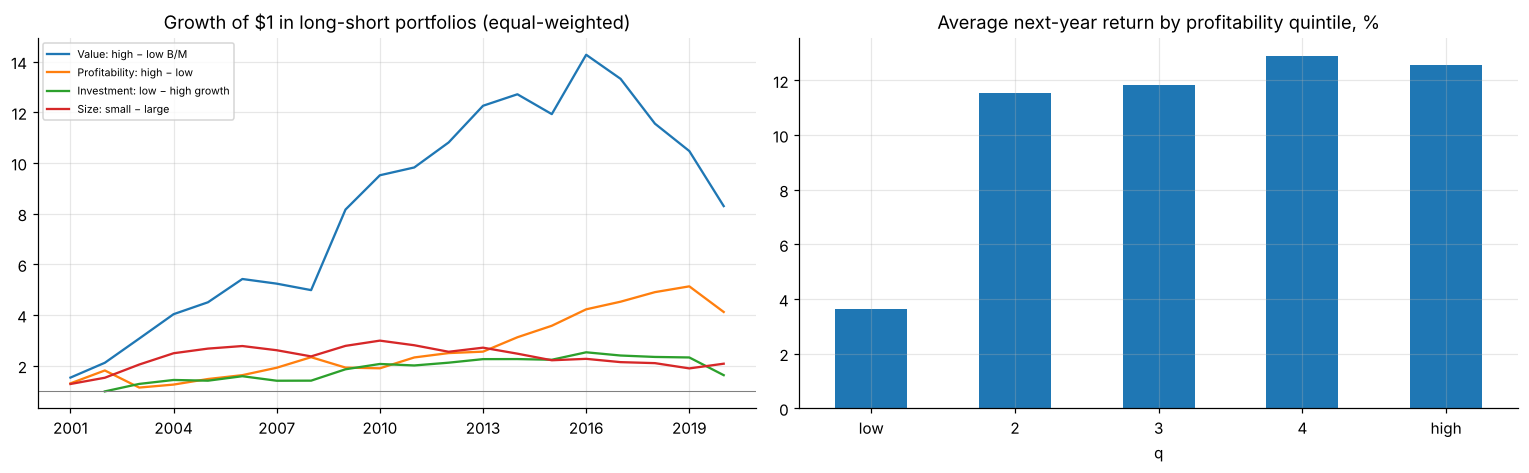

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
cum = pd.DataFrame({n: (1 + spreads[(n, "equal-weighted")] * s).cumprod() for n, s in
                    [("Value (book-to-market)", 1), ("Profitability (operating ROA)", 1), ("Investment (asset growth)", -1), ("Size (market value)", -1)]})
cum.columns = ["Value: high − low B/M", "Profitability: high − low", "Investment: low − high growth", "Size: small − large"]
cum.index = cum.index + 1; cum.plot(ax=ax[0]); ax[0].set_title("Growth of $1 in long-short portfolios (equal-weighted)"); int_years(ax[0]); ax[0].legend(fontsize=7)
ax[0].axhline(1, color="grey", lw=0.7)
ew, _ = sorts("op"); (100 * ew.mean()).plot.bar(ax=ax[1], rot=0, color="C0"); ax[1].set_xticklabels(["low", "2", "3", "4", "high"])
ax[1].set_title("Average next-year return by profitability quintile, %")
plt.tight_layout(); plt.savefig(IMG / "us_factor_portfolios.png", bbox_inches="tight"); plt.show()

## Part 2 · Payout policy in the US and Canada
Compustat Global leaves dividends blank for many firms, so a blank cannot be read as "no dividend". Compustat North America reports zero dividends explicitly (dividends are missing for under 2% of firm-years), so this part uses North America only.

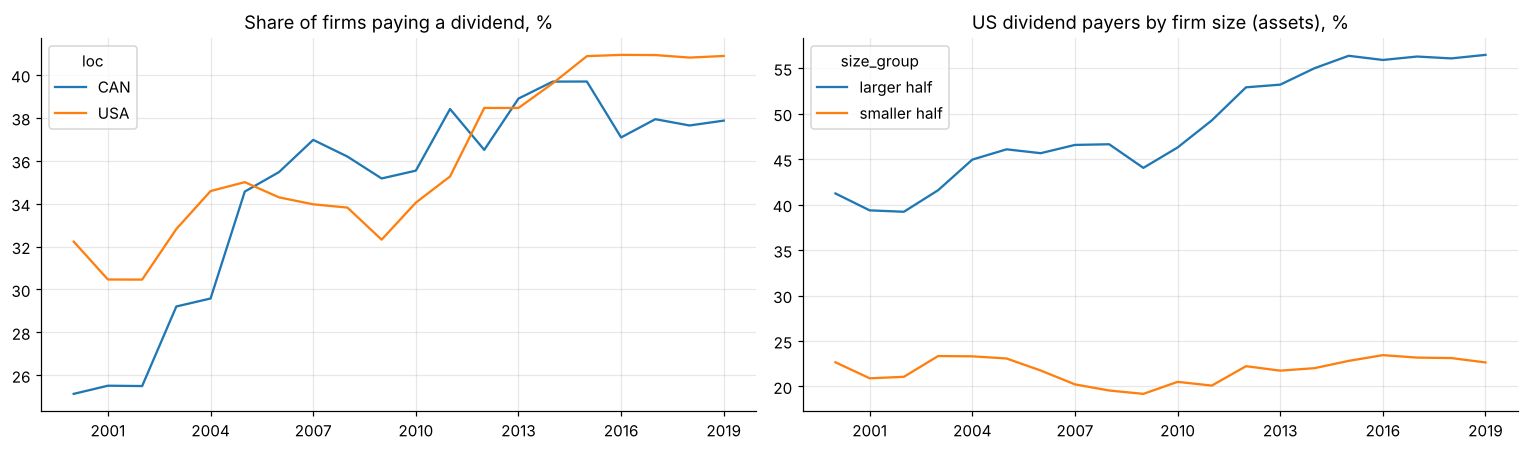

,payers 2000-02 %,payers 2017-19 %,payers among profitable firms 2017-19 %,median payout ratio of payers 2017-19
loc,,,,
CAN,25.38,37.82,63.67,0.54
USA,31.10,40.87,58.56,0.46


In [4]:
nam = p[na & p.fyear.le(2019)].copy()
nam["payer"] = (nam.x_dvt > 0).astype(float).where(nam.x_dvt.notna())
nam["size_group"] = np.where(nam.groupby("fyear")["size"].transform(lambda v: v >= v.median()), "larger half", "smaller half")
py = nam.groupby(["fyear", "loc"]).payer.mean().unstack() * 100
pys = nam[nam["loc"].eq("USA")].groupby(["fyear", "size_group"]).payer.mean().unstack() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
py.plot(ax=ax[0]); ax[0].set_title("Share of firms paying a dividend, %"); int_years(ax[0])
pys.plot(ax=ax[1]); ax[1].set_title("US dividend payers by firm size (assets), %"); int_years(ax[1])
plt.tight_layout(); plt.savefig(IMG / "dividend_payers.png", bbox_inches="tight"); plt.show()
nam["payout_ratio"] = (nam.x_dvt / nam.x_ib.where(nam.x_ib > 0)).clip(0, 2)
pay = pd.DataFrame({"payers 2000-02 %": nam[nam.fyear.between(2000, 2002)].groupby("loc").payer.mean() * 100,
                    "payers 2017-19 %": nam[nam.fyear.between(2017, 2019)].groupby("loc").payer.mean() * 100,
                    "payers among profitable firms 2017-19 %": nam[nam.fyear.between(2017, 2019) & nam.x_ib.gt(0)].groupby("loc").payer.mean() * 100,
                    "median payout ratio of payers 2017-19": nam[nam.fyear.between(2017, 2019) & nam.payer.eq(1)].groupby("loc").payout_ratio.median()})
pay.to_csv(DATA / "dividend_payers_north_america.csv"); pay.round(2)

**Lintner model:** ΔD_t = a + b·D_(t−1) + c·E_t, scaled by lagged assets, for firms that paid a dividend in both years. Speed of adjustment = −b (1 = dividends close the whole gap to their target each year, 0 = they never move). A small c means dividends barely respond to this year's earnings.

In [5]:
import statsmodels.formula.api as smf
A1 = lag("x_at"); p["D"] = p.x_dvt / A1; p["D1"] = lag("x_dvt") / A1; p["E"] = p.x_ib / A1; p["dD"] = p.D - p.D1
ln = p[na & (p.x_dvt > 0) & (lag("x_dvt") > 0)].dropna(subset=["dD", "D1", "E"]).copy()
for c in ["dD", "D1", "E"]: ln[c] = ln[c].clip(ln[c].quantile(0.01), ln[c].quantile(0.99))
ln["period"] = np.where(ln.fyear <= 2009, "2001-2009", "2010-2020")
rows = []
for key, d in list(ln.groupby("loc")) + [(f"USA {k}", d) for k, d in ln[ln["loc"].eq("USA")].groupby("period")]:
    m_ = smf.ols("dD ~ D1 + E", d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d.gvkey)[0]})
    rows.append((key, -m_.params["D1"], m_.tvalues["D1"], m_.params["E"], m_.tvalues["E"], int(m_.nobs)))
lint = pd.DataFrame(rows, columns=["group", "speed of adjustment", "t (D1)", "earnings sensitivity c", "t (E)", "obs"]).set_index("group")
lint.to_csv(DATA / "lintner_north_america.csv"); lint.style.format(precision=3)

,speed of adjustment,t (D1),earnings sensitivity c,t (E),obs
group,,,,,
CAN,0.222,-6.982,0.031,1.763,5840
USA,0.151,-8.029,-0.005,-1.083,27863
USA 2001-2009,0.145,-6.183,0.001,0.227,13191
USA 2010-2020,0.157,-8.349,-0.014,-2.341,14672


## Findings
* **Value and profitability premiums show up clearly in equal-weighted US portfolios** (2001-2020, approximate annual returns). The cheapest book-to-market quintile beat the most expensive by 13.3 points a year (t = 2.6), and the most profitable quintile beat the least profitable by 8.9 points (t = 2.3).
* **Most of the profitability effect sits in the bottom quintile.** Loss-making firms returned 3.6% a year, against 11.5-12.9% for every other quintile. Avoiding the least profitable fifth of stocks captured almost the whole premium.
* **Value-weighted, the premiums shrink.** Value is +3.2 points (t = 0.5) and profitability +7.2 (t = 1.5). The value premium also reversed from 2017, in line with the well-documented "death of value" in large caps.
* **Size and investment effects are weak.** Small caps beat large caps in the equal-weighted sort (+4.5 points, not significant). Low-asset-growth firms did not reliably beat high-growth firms in this sample.
* **Dividends made a comeback in North America.** The share of US firms paying a dividend rose from 31% (2000-02) to 41% (2017-19), and in Canada from 25% to 38%. The rise is entirely among larger firms (from 41% to 56% of the larger half). Among smaller firms the payer share has stayed near 22% for two decades.
* **Dividends are smooth and barely respond to earnings.** The Lintner speed of adjustment is 0.15 for US payers and 0.22 in Canada: firms close only 15-22% of the gap to their target each year. US dividends do not respond to current earnings at all. US payout policy runs on stability and, increasingly, on buybacks, which this extract does not cover.